

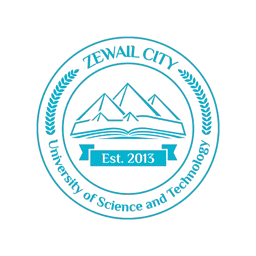


In [1]:
!pip install -q sympy numpy matplotlib pandas

# BOX 11.7 A Computer Model for Schwarzschild Orbits

We want to find a computer algorithm for evaluating $r$ and $\phi$ at discrete proper times separated by a fixed (small) $\Delta\tau$ so that their values represent good approximations (at the same discrete times) to the solutions to

$$
\frac{d^2r}{d\tau^2} = -\frac{GM}{r^2} + \frac{\ell^2}{r^3} - \frac{3GM\ell^2}{r^4} \quad \text{and} \quad \frac{d\phi}{d\tau} = \frac{\ell}{r^2} \tag{11.24}
$$

respectively. The main step in creating such an algorithm is to replace the derivatives in the differential equations with finite differences that represent good approximations to the required derivatives. To find a suitable difference for the double-derivative in the first equation, consider these Taylor series expansions:

$$
r(\tau_n + \Delta\tau) = r(\tau_n) + \left[ \frac{dr}{d\tau} \right]_{\text{at } \tau_n} \Delta\tau + \frac{1}{2} \left[ \frac{d^2r}{d\tau^2} \right]_{\text{at } \tau_n} \Delta\tau^2 + \frac{1}{6} \left[ \frac{d^3r}{d\tau^3} \right]_{\text{at } \tau_n} \Delta\tau^3 + O(\Delta\tau^4) \tag{11.25}
$$

$$
r(\tau_n - \Delta\tau) = r(\tau_n) - \left[ \frac{dr}{d\tau} \right]_{\text{at } \tau_n} \Delta\tau + \frac{1}{2} \left[ \frac{d^2r}{d\tau^2} \right]_{\text{at } \tau_n} \Delta\tau^2 - \frac{1}{6} \left[ \frac{d^3r}{d\tau^3} \right]_{\text{at } \tau_n} \Delta\tau^3 + O(\Delta\tau^4) \tag{11.26}
$$

where $\tau_n$ is the value of the proper time at the $n$th time step and $O(\Delta\tau^4)$ means that the remaining terms are of order of $\Delta\tau^4$ or smaller. Define $r_{n+1} \equiv r(\tau_n + \Delta\tau)$, $r_n \equiv r(\tau_n)$, and $r_{n-1} = r(\tau_n - \Delta\tau)$. Note if we add the two power series above, the odd powers cancel out, and if we then subtract $2r_n$ to kill the first even term, we get

$$
r_{n+1} - 2r_n + r_{n-1} = \left[ \frac{d^2r}{d\tau^2} \right]_{\text{at } \tau_n} \Delta\tau^2 + 2O(\Delta\tau^4) \tag{11.27}
$$

Note that if we drop the terms summarized by $2O(\Delta\tau^4)$, we will only be making an error that is roughly $\Delta\tau^2$ smaller than the second-derivative term: we therefore say that the difference expression on the left is a "second-order-accurate" approximation to $[d^2r/d\tau^2]\Delta\tau^2$ evaluated at $\tau_n$. As long as we choose $\Delta\tau$ to be sufficiently small, this should be good enough. It also turns out that using *at least* second-order-accurate approximations greatly increases the probability that the numerical solution will remain stable as the calculation proceeds.

So if we drop the $O(\Delta\tau^4)$ term in equation 11.27 and substitute the right side of the first of equations 11.24 for second derivative, we get

$$
r_{n+1} - 2r_n + r_{n-1} = \Delta\tau^2 \left[ -\frac{GM}{r^2} + \frac{\ell^2}{r^3} - \frac{3GM\ell^2}{r^4} \right]_{\text{at } \tau_n} = \Delta\tau^2 \left[ -\frac{GM}{r_n^2} + \frac{\ell^2}{r_n^3} - \frac{3GM\ell^2}{r_n^4} \right] \tag{11.28}
$$

Solving for $r_{n+1}$ yields equation 11.18.


Now consider the following Taylor series for $r$ and $\phi$ expanded about the instant $\tau_{n+1/2} \equiv \tau_n + \frac{1}{2}\Delta\tau$ halfway between $\tau_n$ and $\tau_{n+1}$:

$$
r_{n+1} = r_{n+1/2} + \left[ \frac{dr}{d\tau} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau) + \frac{1}{2} \left[ \frac{d^2r}{d\tau^2} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau)^2 + O(\Delta\tau^3) \tag{11.29a}
$$

$$
r_{n} = r_{n+1/2} - \left[ \frac{dr}{d\tau} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau) + \frac{1}{2} \left[ \frac{d^2r}{d\tau^2} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau)^2 - O(\Delta\tau^3) \tag{11.29b}
$$

$$
\phi_{n+1} = \phi_{n+1/2} + \left[ \frac{d\phi}{d\tau} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau) + \frac{1}{2} \left[ \frac{d^2\phi}{d\tau^2} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau)^2 + O(\Delta\tau^3) \tag{11.29c}
$$

$$
\phi_{n} = \phi_{n+1/2} - \left[ \frac{d\phi}{d\tau} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau) + \frac{1}{2} \left[ \frac{d^2\phi}{d\tau^2} \right]_{\text{at } \tau_{n+1/2}} (\tfrac{1}{2}\Delta\tau)^2 - O(\Delta\tau^3) \tag{11.29d}
$$

where $r_{n+1} \equiv r(\tau_n + \Delta\tau) = r(\tau_{n+1/2} + \frac{1}{2}\Delta\tau)$, $r_{n+1/2} \equiv r(\tau_{n+1/2})$, and $r_n \equiv r(\tau_n) \equiv r(\tau_{n+1/2} - \frac{1}{2}\Delta\tau)$, and similarly for $\phi$.

---
**Exercise 11.7.1.**
- Use these Taylor series to show that $\frac{1}{2}(r_{n+1} + r_n)$ is a second-order-accurate approximation for $r_{n+1/2}$.
- and that $\phi_{n+1} - \phi_n$ is a second-order-accurate approximation for $[d\phi/d\tau]\Delta\tau$ evaluated at $\tau_{n+1/2}$.


In [2]:
import sympy as sp
from IPython.display import display, Markdown

# Define symbols
tau = sp.Symbol('tau')
delta_tau = sp.Symbol('Delta_tau')
tau_n = sp.Symbol('tau_n')

# Define r and phi as functions of tau
r = sp.Function('r')
phi = sp.Function('phi')

In [3]:
# r(τ_{n+1/2} ± Δτ/2)
r_n_plus_1 = (r(tau)+ r(tau).diff(tau)    * (delta_tau/2) + sp.Rational(1,2) * r(tau).diff(tau, 2) * (delta_tau/2)**2)
r_n_plus_1

Delta_tau**2*Derivative(r(tau), (tau, 2))/8 + Delta_tau*Derivative(r(tau), tau)/2 + r(tau)

In [4]:
r_n_expr   = (r(tau) - r(tau).diff(tau)    * (delta_tau/2) + sp.Rational(1,2) * r(tau).diff(tau, 2) * (delta_tau/2)**2)
r_n_expr

Delta_tau**2*Derivative(r(tau), (tau, 2))/8 - Delta_tau*Derivative(r(tau), tau)/2 + r(tau)

In [5]:
# phi(τ_{n+1/2} ± Δτ/2)
phi_n_plus_1 = (phi(tau) + phi(tau).diff(tau)    * (delta_tau/2) + sp.Rational(1,2) * phi(tau).diff(tau, 2) * (delta_tau/2)**2)
phi_n_plus_1

Delta_tau**2*Derivative(phi(tau), (tau, 2))/8 + Delta_tau*Derivative(phi(tau), tau)/2 + phi(tau)

In [6]:
phi_n_expr  = (phi(tau) - phi(tau).diff(tau)    * (delta_tau/2) + sp.Rational(1,2) * phi(tau).diff(tau, 2) * (delta_tau/2)**2)
phi_n_expr

Delta_tau**2*Derivative(phi(tau), (tau, 2))/8 - Delta_tau*Derivative(phi(tau), tau)/2 + phi(tau)

In [7]:
# Compute expressions
r_avg    = sp.simplify((r_n_plus_1 + r_n_expr) / 2)
phi_diff = sp.simplify(phi_n_plus_1 - phi_n_expr)

In [8]:
# Evaluate at τ = τ_n + Δτ/2
tau_half = tau_n + delta_tau / 2          # τ_{n+1/2}

r_avg_eval    = r_avg.subs(tau, tau_half)
phi_diff_eval = phi_diff.subs(tau, tau_half)

In [9]:
display(Markdown(r"$\frac{1}{2}(r_{n+1} + r_n)$:"))
display(Markdown(r"$\tau = \tau_n + \Delta\tau/2$:"))
display(r_avg_eval)

$\frac{1}{2}(r_{n+1} + r_n)$:

$\tau = \tau_n + \Delta\tau/2$:

Delta_tau**2*Subs(Derivative(r(tau), (tau, 2)), tau, Delta_tau/2 + tau_n)/8 + r(Delta_tau/2 + tau_n)

$$ ∴
\boxed{
\frac{1}{2}(r_{n+1} + r_n)
= r\!\left(\tau_n + \tfrac{\Delta\tau}{2}\right)
+ \mathcal{O}(\Delta\tau^2) ≈ r_{n+\frac{1}{2}}
}
$$

In [10]:
display(Markdown(r"$\phi_{n+1} - \phi_n$:"))
display(Markdown(r"$\tau = \tau_n + \Delta\tau/2$:"))
display(phi_diff_eval)

$\phi_{n+1} - \phi_n$:

$\tau = \tau_n + \Delta\tau/2$:

Delta_tau*Subs(Derivative(phi(tau), tau), tau, Delta_tau/2 + tau_n)


$$ ∴ \boxed{\phi_{n+1} - \phi_n = \Delta\tau \left.\frac{d\phi}{d\tau}\right|_{\tau_{n+1/2}}}$$


Therefore, a second-order-accurate approximation for $d\phi/d\tau = \ell/r^2$ is

$$
\phi_{n+1} - \phi_n = \frac{\ell \Delta\tau}{r_{n+1/2}^2} = \frac{\ell \Delta\tau}{\frac{1}{4}(r_{n+1} + r_n)^2} \tag{11.30}
$$

Adding $\phi_n$ to both sides yields equation 11.19.

The common element in these approximations is that the differences (or the sum in the case of $r_{n+1/2}$) are symmetrical about the evaluation point. We call these **centered difference approximations**.

All that remains now to complete the algorithm is to choose appropriate values for $\Delta\tau$ and $\ell$ and initial values of $r$ and $\phi$. We fundamentally need to choose (as in the case of Newtonian mechanics) an initial position and velocity for both coordinates to define the orbit. It is easiest to take our initial point to be at an extreme point in the orbit (i.e., to be a point where $dr/d\tau = 0$) and define $\phi$ to be zero there. Mindful that we want to choose centered approximations, let's define this point in the orbit to occur at time $\tau_{1/2}$ a half step after $\tau_0$. We can choose our initial radius $r_{1/2}$ arbitrarily, but requiring that $dr/d\tau = 0$ at this time means that $r_1 - r_0 \approx 0$, implying that $r_1 = r_0 = r_{1/2}$. Choosing an initial angular speed $[d\phi/d\tau]_{1/2}$ at radius $r_{1/2}$ allows us to calculate the constant $\ell = r_{1/2}^2 [d\phi/d\tau]_{1/2}$, and since we are taking $\phi_{1/2} = 0$, we also have $\phi_1 = +\frac{1}{2} [d\phi/d\tau]_{1/2} \Delta\tau$. Given a good choice for $\Delta\tau$, we have what we need to calculate $r$ and $\phi$ at future time steps.

The easiest way to choose $\Delta\tau$ is to choose it to be a small fraction (something like 1/500) of the time required for a circular orbit of radius $r_{1/2}$. This will ensure that for all but the most extremely non-circular orbits, $\Delta\tau$ will be small enough so that neither $r$ nor $\phi$ changes much during a time step, which in turn means that ignoring high-order terms in the Taylor series we have used will be a sound approximation.

One can calculate the proper time period for a circular orbit with a given radius $r_c$ as follows. For a circular orbit, $d^2r_c/d\tau^2 = 0$. If you substitute this into the first relation in equation 11.24 and solve for $\ell$, you can show that

$$
\frac{\ell_c}{GM} = \frac{r_c/GM}{\sqrt{(r_c/GM) - 3}} \tag{11.31}
$$

**Exercise 11.7.2.** Verify this.


In [11]:
# Define symbols
r, GM, ell = sp.symbols('r GM ell', positive=True)
u = sp.Symbol('u', positive=True)  # u = r_c / GM

# Radial equation with d²r/dτ² = 0
radial_eq = -GM/r**2 + ell**2/r**3 - 3*GM*ell**2/r**4
radial_eq

-3*GM*ell**2/r**4 - GM/r**2 + ell**2/r**3

In [12]:
# Multiply through by r⁴ to clear denominators
eq_cleared = sp.simplify(radial_eq * r**4)
display(eq_cleared)

# Solve for ℓ²
ell_sq_solutions = sp.solve(eq_cleared, ell**2)
ell_sq = ell_sq_solutions[0]

# Solving for $\\ell^2$
display(Markdown(r"$\ell^2$:"))
display(ell_sq)

-3*GM*ell**2 - GM*r**2 + ell**2*r

$\ell^2$:

GM*r**2/(-3*GM + r)

In [13]:
# Substitute r
display(Markdown(r"$\frac{\ell}{GM}$:"))

ell_over_GM = ell_sq / GM**2
ell_over_GM = sp.sqrt(ell_over_GM)
ell_over_GM

$\frac{\ell}{GM}$:

r*sqrt(1/(-3*GM + r))/sqrt(GM)

$$ ∴\boxed{\frac{\ell}{GM} = \frac{r/GM}{\sqrt{(r/GM) - 3}}}
$$


We can therefore calculate a circular orbit period for all $r > 3GM$ (even though orbits for $r < 6GM$ cannot be stable). Since the angular speed $d\phi/d\tau$ for a circular orbit is constant, the proper time required for a complete orbit at our initial radius $r_{1/2}$ is, then,

$$
\tau_c = \left[ \frac{d\tau}{d\phi} \right]_c 2\pi = 2\pi \frac{r_{1/2}^2}{\ell_c} \tag{11.32}
$$

We can therefore set $\Delta\tau = \tau_c / 500$ or so, and be pretty comfortable that this will be small enough.

If we go this route, we have to calculate the angular speed $[d\phi/d\tau]_c = \ell_c/r_{1/2}^2$ for a circular orbit anyway, it is also pretty convenient to specify the object's initial angular speed $[d\phi/d\tau]_{1/2}$ as a fraction of that speed. This saves us from randomly guessing what an appropriate angular speed might be.

Finally, a computer can deal with unitless numbers, so it is convenient to express $r$, $\tau$, and $\ell$ in units of the distance unit $GM$. This amounts to nothing more than setting $GM = 1$ in all of the equations in this box that explicitly refer to $GM$.

---

# Problem 11.11

Implement the computer model described in box 11.7 using either a spreadsheet, a computer mathematics tool such as Mathematica, or a computer programming language such as C. Set your initial radius to $50GM$ and your initial angular speed to about 0.75 times the circular orbit speed, graph $r(\phi)$, and see if you can reproduce the results shown in figure 11.1. When your implementation seems to be working well, experiment with some other initial conditions. How does changing the initial radius affect your results? Changing the initial angular speed? Submit some kind of printout or file that shows how you implemented the computer model, and printouts of graphs of $r(\phi)$ for at least three cases you examined.

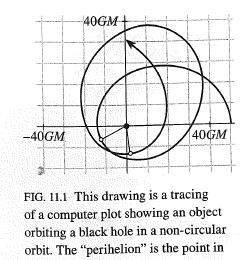

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# All lengths in units of GM (so GM = 1)
GM = 1.0

In [15]:
def circular_ell(r_c, GM=1.0):
    """Angular momentum for circular orbit at radius r_c (eq. 11.31)."""
    u = r_c / GM
    return GM * u / np.sqrt(u - 3)

In [16]:
def integrate_orbit(r_init, ell, GM=1.0, n_steps=1000, dtau_frac=1/500):
    """
    Integrate Schwarzschild orbit using centered-difference algorithm.

    Initial point is at tau_{1/2}: dr/dtau = 0 there, so r_1 = r_0 = r_init.
    phi starts at 0 at tau_{1/2}.
    """
    # Proper time step ~ 1/500 of circular orbit period at r_init
    # Circular orbit period estimate: T ~ 2*pi*r^(3/2) / sqrt(GM) (Newtonian approx)
    T_approx = 2 * np.pi * r_init**1.5 / np.sqrt(GM)
    dtau = dtau_frac * T_approx

    # Initial conditions: r_1 = r_0 = r_init (since dr/dtau = 0 at start)
    r_n   = r_init
    r_np1 = r_init   # r_{n+1} starts equal to r_n

    # phi_1 = + (1/2) * (ell/r_{1/2}^2) * dtau  (eq. 11.19 first step)
    phi_n = 0.5 * (ell / r_init**2) * dtau

    r_vals   = [r_init]
    phi_vals = [0.0]

    def accel(rn):
        """d²r/dτ² from eq. 11.24."""
        return -GM/rn**2 + ell**2/rn**3 - 3*GM*ell**2/rn**4

    for _ in range(n_steps):
        # eq. 11.18: r_{n+1} = 2*r_n - r_{n-1} + dtau^2 * accel(r_n)
        r_np2 = 2*r_np1 - r_n + dtau**2 * accel(r_np1)

        # eq. 11.19 / 11.30: phi_{n+1} = phi_n + ell*dtau / (0.5*(r_{n+2}+r_{n+1}))^2
        r_half = 0.5 * (r_np2 + r_np1)
        phi_np1 = phi_n + ell * dtau / r_half**2

        r_vals.append(r_np1)
        phi_vals.append(phi_n)

        # stop if orbit falls inside event horizon
        if r_np1 < 2*GM:
            print("Orbit crossed event horizon — stopping.")
            break

        r_n, r_np1 = r_np1, r_np2
        phi_n = phi_np1

    return np.array(r_vals), np.array(phi_vals)

In [17]:
r0   = 50.0 * GM
ell_c = circular_ell(r0)
ell   = 0.75 * ell_c

r_vals, phi_vals = integrate_orbit(r0, ell, n_steps=10000)


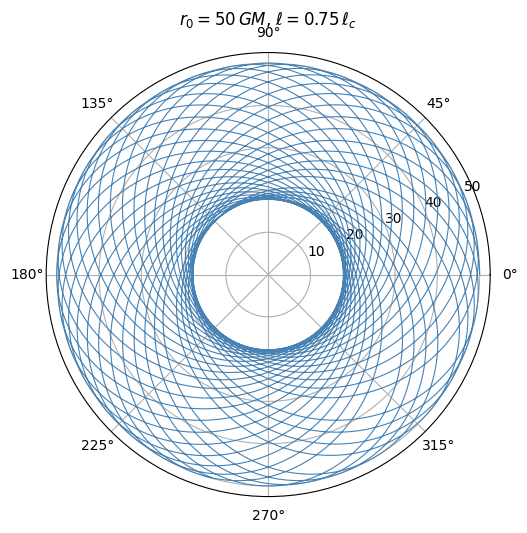

r_min = 17.79 GM,  r_max = 50.00 GM


In [18]:
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'projection': 'polar'})
ax.plot(phi_vals, r_vals, lw=0.8, color='steelblue')

ax.set_title(r"$r_0 = 50\,GM$, $\ell = 0.75\,\ell_c$", pad=20)

ax.set_rmax(r_vals.max() * 1.05)

plt.subplots_adjust(top=0.85)
plt.savefig("orbit_fig11_1.png", dpi=150)
plt.show()

print(f"r_min = {r_vals.min():.2f} GM,  r_max = {r_vals.max():.2f} GM")

Orbit crossed event horizon — stopping.


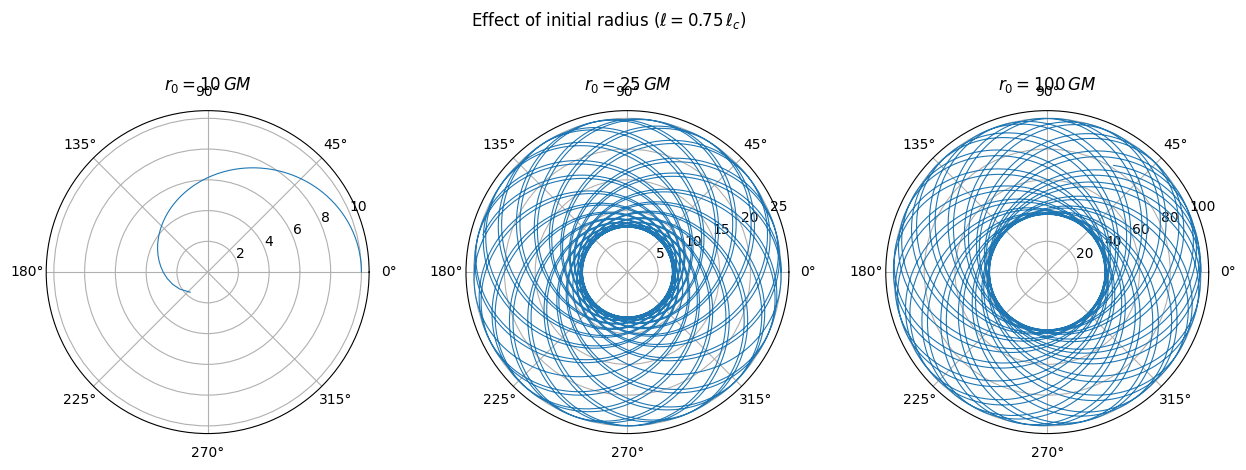

In [19]:
radii  = [10*GM, 25*GM, 100*GM]
factor = 0.75

fig, axes = plt.subplots(1, 3, figsize=(15, 5),
                         subplot_kw={'projection': 'polar'})

for ax, r0 in zip(axes, radii):
    ell = factor * circular_ell(r0)
    r_vals, phi_vals = integrate_orbit(r0, ell, n_steps=10_000)
    ax.plot(phi_vals, r_vals, lw=0.8)
    ax.set_title(rf"$r_0 = {int(r0/GM)}\,GM$", pad=15)
    ax.set_rmax(r_vals.max() * 1.05)

fig.suptitle(r"Effect of initial radius ($\ell = 0.75\,\ell_c$)", y=0.98)

plt.subplots_adjust(top=0.80, wspace=0.3)

plt.savefig("orbit_radius_comparison.png", dpi=150)
plt.show()

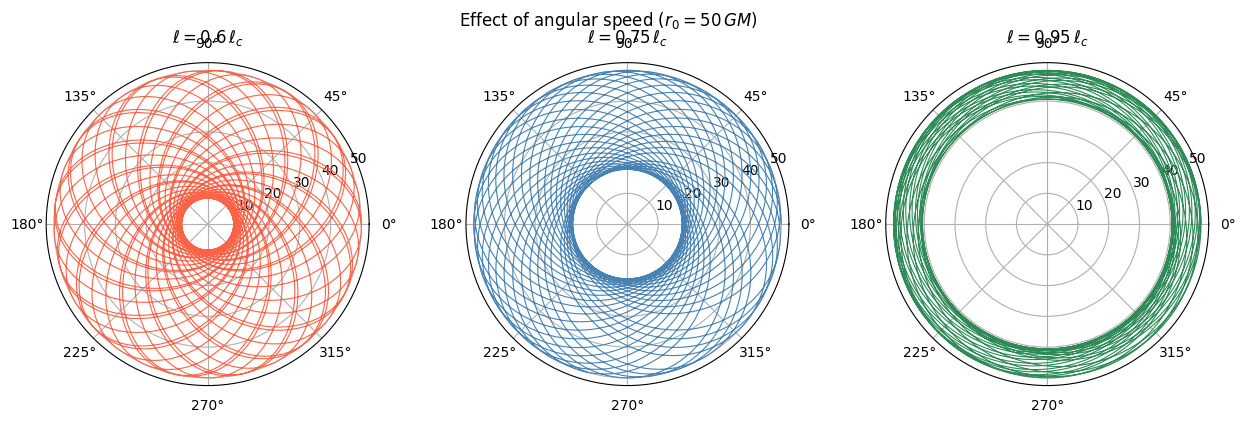

In [20]:
r0      = 50.0 * GM
factors = [0.60, 0.75, 0.95]
colors  = ['tomato', 'steelblue', 'seagreen']

fig, axes = plt.subplots(1, 3, figsize=(15, 5),
                         subplot_kw={'projection': 'polar'})

for ax, f, c in zip(axes, factors, colors):
    ell = f * circular_ell(r0)
    r_vals, phi_vals = integrate_orbit(r0, ell, n_steps=10_000)
    ax.plot(phi_vals, r_vals, lw=0.8, color=c)
    ax.set_title(rf"$\ell = {f}\,\ell_c$", pad=15)
    ax.set_rmax(r_vals.max() * 1.05)

fig.suptitle(r"Effect of angular speed ($r_0 = 50\,GM$)", y=0.98)

plt.subplots_adjust(top=0.99, wspace=0.3)

plt.savefig("orbit_speed_comparison.png", dpi=150)
plt.show()

Orbit crossed event horizon — stopping.


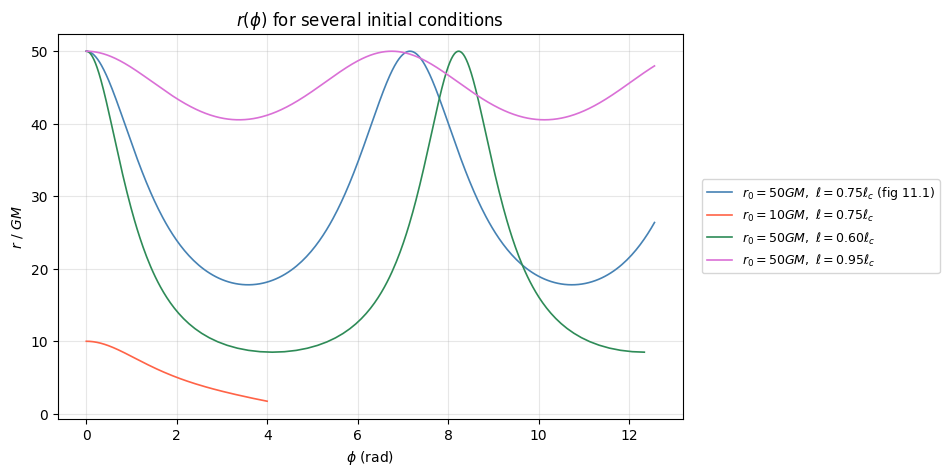

In [21]:
cases = [
    (50*GM, 0.75, 'steelblue', r'$r_0=50GM,\ \ell=0.75\ell_c$ (fig 11.1)'),
    (10*GM, 0.75, 'tomato',    r'$r_0=10GM,\ \ell=0.75\ell_c$'),
    (50*GM, 0.60, 'seagreen',  r'$r_0=50GM,\ \ell=0.60\ell_c$'),
    (50*GM, 0.95, 'orchid',    r'$r_0=50GM,\ \ell=0.95\ell_c$'),
]

fig, ax = plt.subplots(figsize=(10, 5))
for r0, f, c, label in cases:
    ell = f * circular_ell(r0)
    r_vals, phi_vals = integrate_orbit(r0, ell, n_steps=300_000)
    # save data in csv
    data = np.column_stack((phi_vals, r_vals))
    filename = f"orbit_r0_{int(r0/GM)}_ell_{f:.2f}.csv"
    np.savetxt(filename, data, delimiter=",", header="phi,r", comments="")
    # wrap phi to [0, 4π] for a readable Cartesian slice
    mask = phi_vals < 4*np.pi
    ax.plot(phi_vals[mask], r_vals[mask], lw=1.2, color=c, label=label)

ax.set_xlabel(r"$\phi$ (rad)")
ax.set_ylabel(r"$r\ /\ GM$")
ax.set_title(r"$r(\phi)$ for several initial conditions")
ax.grid(True, alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=9)
plt.subplots_adjust(right=0.75)
plt.savefig("orbit_r_phi_cartesian.png", dpi=150)
plt.show()

---